---
title: "NBRplus-Lawu-Geemap-Python: NBRplus_Lawu (1).ipynb"
---


# Burned Area Mapping of Mount Lawu Using NBR+ and Sentinel-2

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/1x1Lp_1EP8jjy7lj25k9P0Nnx1NVULYCU?usp=sharing)
[![Open in Earth Engine](https://img.shields.io/badge/Open%20in-Earth%20Engine-4285F4?style=flat-square&logo=google&logoColor=white)](https://code.earthengine.google.com/457addfc0dcb9d8e840be1ac7d5e2c4d?hl=id)
[![GitHub](https://img.shields.io/badge/GitHub-NBRplus--Lawu-100000?style=flat-square&logo=github&logoColor=white)](https://github.com/Defani/NBRplus-Lawu-Geemap-Python)

**Author:** Defani Arman Alfitriansyah

<div align="left">
  <a href="https://linkedin.com/in/defaniarmanalfitriansyah"><img src="https://img.shields.io/badge/LinkedIn-0077B5?style=flat-square&logo=linkedin&logoColor=white"/></a>
  <a href="https://medium.com/@defaniarman"><img src="https://img.shields.io/badge/Medium-12100E?style=flat-square&logo=medium&logoColor=white"/></a>
  <a href="https://tiktok.com/@defaniarman"><img src="https://img.shields.io/badge/TikTok-000000?style=flat-square&logo=tiktok&logoColor=white"/></a>
  <a href="https://www.instagram.com/de.fanii"><img src="https://img.shields.io/badge/Instagram-E4405F?style=flat-square&logo=instagram&logoColor=white"/></a>
  <a href="https://www.kaggle.com/defani123"><img src="https://img.shields.io/badge/Kaggle-20BEFF?style=flat-square&logo=kaggle&logoColor=white"/></a>
  <a href="https://rpubs.com/defanii"><img src="https://img.shields.io/badge/RPubs-75AADB?style=flat-square&logo=r&logoColor=white"/></a>
  <a href="https://www.behance.net/defaniarman"><img src="https://img.shields.io/badge/Behance-1769FF?style=flat-square&logo=behance&logoColor=white"/></a>
  <a href="mailto:defaniarman@gmail.com"><img src="https://img.shields.io/badge/Email-D14836?style=flat-square&logo=gmail&logoColor=white"/></a>
</div>


---

## Overview

This notebook maps burned areas from the Mount Lawu forest fire (August 30 – September 29, 2023) using the **Normalized Burn Ratio Plus (NBR+)** index applied to **Sentinel-2 SR Harmonized** imagery via Google Earth Engine.

The bi-temporal approach computes the difference between pre-fire and post-fire NBR+ composites (dNBR+) to delineate and classify burn severity. NBR+ was proposed by Alcaras et al. (2022) as an enhancement over the classical NBR: by incorporating the Blue (B2) and Green (B3) bands alongside NIR (B8A) and SWIR2 (B12), NBR+ inherently suppresses false positives from water bodies and clouds without requiring external masks.

**Index formula (Alcaras et al., 2022):**

$$\text{NBR+} = \frac{B12 - B8A - B3 - B2}{B12 + B8A + B3 + B2}$$

**Bi-temporal delta:**

$$\Delta\text{NBR+} = \text{NBR+}_{\text{post-fire}} - \text{NBR+}_{\text{pre-fire}}$$

| Study Area | Mount Lawu, Central Java / East Java border, Indonesia |
|---|---|
| Coordinates | 111°11'39" E, 7°37'37" S |
| Satellite | Sentinel-2A SR Harmonized |
| Pre-fire composite | August 1–29, 2023 (median) |
| Post-fire composite | October 1–31, 2023 (median) |
| Spatial resolution | 20 m |


---

## 1. Install Dependencies


In [1]:
!pip install geemap cartopy --quiet


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 79.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 101.7 MB/s eta 0:00:00


---

## 2. Import Libraries and Authenticate


In [2]:
import ee
import geemap
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
from geemap import cartoee

# Authenticate and initialize Google Earth Engine
ee.Authenticate()
ee.Initialize(project='ee-defaniarman')

# Global plot style
plt.rcParams['font.family'] = 'serif'


---

## 3. Define Area of Interest (AOI)

The AOI covers the Mount Lawu forest boundary spanning Karanganyar (Central Java), Magetan, and Ngawi (East Java).


In [3]:
lawu = ee.Geometry.Polygon([[
    [111.17372873826915, -7.647583870310043],
    [111.24342325731212, -7.647583870310043],
    [111.24342325731212, -7.55587155368799 ],
    [111.17372873826915, -7.55587155368799 ],
    [111.17372873826915, -7.647583870310043]
]])

# Bounding box [lon_min, lat_min, lon_max, lat_max] for cartoee rendering
REGION = [111.1737, -7.6476, 111.2434, -7.5558]


---

## 4. Load and Preprocess Sentinel-2 SR Collection

Cloud masking is applied using the Cloud Score+ product (`cs_cdf >= 0.6`). Only scenes with less than 20% cloud cover are retained. Pre-fire and post-fire composites are built from median pixel values.


In [4]:
def mask_s2_clouds(image):
    """Mask clouds using Cloud Score+ continuous confidence (cs_cdf >= 0.6)."""
    cs = image.select('cs_cdf')
    return image.updateMask(cs.gte(0.6))

s2_collection = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(lawu)
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
    .linkCollection(
        ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED'),
        ['cs_cdf']
    )
    .map(mask_s2_clouds)
)

pre_fire  = s2_collection.filterDate('2023-08-01', '2023-08-29').median().clip(lawu)
post_fire = s2_collection.filterDate('2023-10-01', '2023-10-31').median().clip(lawu)

print('Pre-fire image size:', pre_fire.bandNames().getInfo())


Pre-fire image size: ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'AOT', 'WVP', 'SCL', 'TCI_R', 'TCI_G', 'TCI_B', 'MSK_CLDPRB', 'MSK_SNWPRB', 'QA10', 'QA20', 'QA60', 'MSK_CLASSI_OPAQUE', 'MSK_CLASSI_CIRRUS', 'MSK_CLASSI_SNOW_ICE', 'cs_cdf']


---

## 5. Compute NBR+ and dNBR+

NBR+ is computed for both the pre-fire and post-fire composites. The bi-temporal delta (dNBR+) isolates fire-induced spectral change. Pixels with dNBR+ >= 0.3 are classified as burned.


In [5]:
def calc_nbr_plus(image):
    """
    Compute NBR+ (Alcaras et al., 2022).

    NBR+ = (B12 - B8A - B3 - B2) / (B12 + B8A + B3 + B2)

    Sentinel-2 bands:
        B2  — Blue  (490 nm)
        B3  — Green (560 nm)
        B8A — Narrow NIR (865 nm)
        B12 — SWIR2 (2190 nm)
    """
    b2  = image.select('B2')
    b3  = image.select('B3')
    b8a = image.select('B8A')
    b12 = image.select('B12')

    numerator   = b12.subtract(b8a).subtract(b3).subtract(b2)
    denominator = b12.add(b8a).add(b3).add(b2)

    return numerator.divide(denominator).rename('nbr_plus')

nbr_plus_pre  = calc_nbr_plus(pre_fire)
nbr_plus_post = calc_nbr_plus(post_fire)

# dNBR+ = post - pre  (positive values indicate fire-driven decrease in NBR+)
d_nbr_plus    = nbr_plus_post.subtract(nbr_plus_pre).rename('d_nbr_plus')

# Binary burned area mask at threshold dNBR+ >= 0.3
burn_mask = d_nbr_plus.gte(0.3).selfMask()


---

## 6. Compute Dynamic Stretch Statistics

Min/max values are derived from the post-fire NBR+ raster over the AOI to produce a data-driven colormap stretch for visualization.


In [6]:
stats = nbr_plus_post.reduceRegion(
    reducer   = ee.Reducer.minMax(),
    geometry  = lawu,
    scale     = 20,
    maxPixels = 1e9
).getInfo()

nbr_min = stats.get('nbr_plus_min', -0.5)
nbr_max = stats.get('nbr_plus_max',  0.5)

print(f'NBR+ range — min: {nbr_min:.4f}, max: {nbr_max:.4f}')


NBR+ range — min: -0.8201, max: 0.4796


---

## 7. Generate 2×3 Visualization Panel

The panel displays six maps for direct comparison:
- **A / B**: False color composites (B11/B8/B4) before and after the fire
- **C**: Post-fire composite overlaid with the burned area mask
- **D / E**: Pre-fire and post-fire NBR+ rasters
- **F**: Burned area mask only


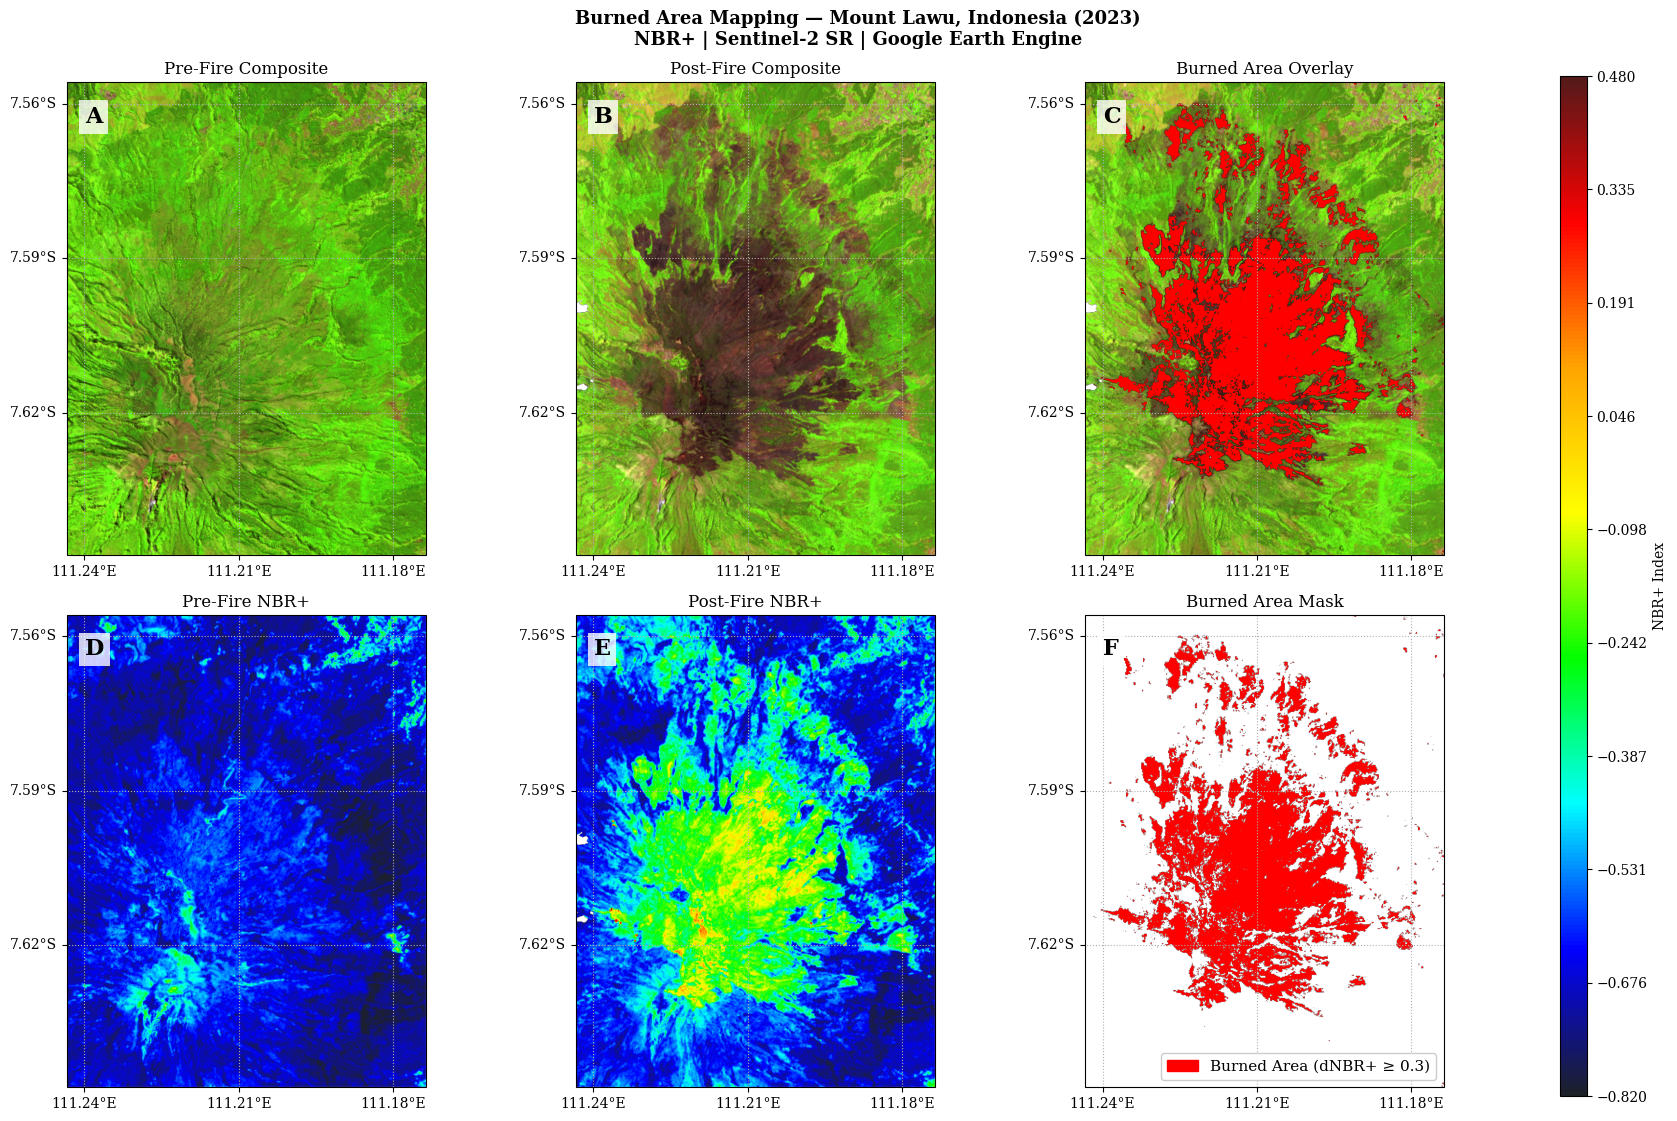

Figure saved as NBRplus_Lawu_Panel.png


In [7]:
# Visualization parameters
VIS_COMPOSITE = {'bands': ['B11', 'B8', 'B4'], 'min': 0,       'max': 4000}
VIS_NBR_PLUS  = {
    'min':     nbr_min,
    'max':     nbr_max,
    'palette': ['#1D2128', '#0000FF', '#00FFFF', '#00FF00',
                '#FFFF00', '#FFA500', '#FF0000', '#541A1A']
}
VIS_BURN      = {'palette': ['#FF0000']}

PANEL_LABELS = ['A', 'B', 'C', 'D', 'E', 'F']
PANEL_TITLES = [
    'Pre-Fire Composite',
    'Post-Fire Composite',
    'Burned Area Overlay',
    'Pre-Fire NBR+',
    'Post-Fire NBR+',
    'Burned Area Mask',
]

def add_panel_label(ax, label):
    ax.text(
        0.05, 0.95, label,
        transform=ax.transAxes,
        fontsize=16, fontweight='bold',
        va='top', ha='left',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='none')
    )

# ── Build figure ──────────────────────────────────────────────────────────────
fig, axs = plt.subplots(
    2, 3, figsize=(18, 12),
    subplot_kw={'projection': ccrs.PlateCarree()}
)
axs = axs.flatten()

# Panel A — Pre-fire composite
cartoee.add_layer(axs[0], pre_fire, vis_params=VIS_COMPOSITE, region=REGION)
cartoee.add_gridlines(axs[0], interval=0.03, linestyle=':')

# Panel B — Post-fire composite
cartoee.add_layer(axs[1], post_fire, vis_params=VIS_COMPOSITE, region=REGION)
cartoee.add_gridlines(axs[1], interval=0.03, linestyle=':')

# Panel C — Post-fire composite + burned area overlay
cartoee.add_layer(axs[2], post_fire,  vis_params=VIS_COMPOSITE, region=REGION)
cartoee.add_layer(axs[2], burn_mask,  vis_params=VIS_BURN,      region=REGION)
cartoee.add_gridlines(axs[2], interval=0.03, linestyle=':')

# Panel D — Pre-fire NBR+
cartoee.add_layer(axs[3], nbr_plus_pre, vis_params=VIS_NBR_PLUS, region=REGION)
cartoee.add_gridlines(axs[3], interval=0.03, linestyle=':')

# Panel E — Post-fire NBR+
cartoee.add_layer(axs[4], nbr_plus_post, vis_params=VIS_NBR_PLUS, region=REGION)
cartoee.add_gridlines(axs[4], interval=0.03, linestyle=':')

# Panel F — Burned area mask only
cartoee.add_layer(axs[5], burn_mask, vis_params=VIS_BURN, region=REGION)
cartoee.add_gridlines(axs[5], interval=0.03, linestyle=':')

# Titles and panel labels
for ax, title, label in zip(axs, PANEL_TITLES, PANEL_LABELS):
    ax.set_title(title, fontsize=12, pad=6)
    add_panel_label(ax, label)

# Legend for Panel F
red_patch = mpatches.Patch(color='#FF0000', label='Burned Area (dNBR+ ≥ 0.3)')
axs[5].legend(handles=[red_patch], loc='lower right', fontsize=11,
              facecolor='white', framealpha=1)

# Shared colorbar for NBR+ panels (D and E)
plt.tight_layout(rect=[0, 0.05, 0.88, 0.95])
cax = fig.add_axes([0.89, 0.075, 0.015, 0.85])
cartoee.add_colorbar(
    axs[4], vis_params=VIS_NBR_PLUS,
    cax=cax, orientation='vertical', label='NBR+ Index'
)
cax.set_yticks(np.linspace(nbr_min, nbr_max, 10))

plt.suptitle(
    'Burned Area Mapping — Mount Lawu, Indonesia (2023)\nNBR+ | Sentinel-2 SR | Google Earth Engine',
    fontsize=13, fontweight='bold', y=0.98
)

plt.savefig('NBRplus_Lawu_Panel.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved as NBRplus_Lawu_Panel.png')


---

## References

- Alcaras, E., Costantino, D., Guastaferro, F., Parente, C., & Pepe, M. (2022). Normalized Burn Ratio Plus (NBR+): A New Index for Sentinel-2 Imagery. *Remote Sensing*, 14, 1727. https://doi.org/10.3390/rs14071727
- Garcia, M. J. L., & Caselles, V. (1991). Mapping burns and natural reforestation using thematic mapper data. *Geocarto International*, 6(1), 31–37. https://doi.org/10.1080/10106049109354290
- Salsabella, R. I., & Arrofiqoh, E. N. (2024). Mapping the severity level of forest fire area in Mount Lawu using Landsat 9 imagery. *JGISE*, 7(2), 151–160. https://doi.org/10.22146/jgise.100721
- USGS. (2022). *Landsat 9 Data Users Handbook v1.0*. NASA.
- Wu, Q. (2020). geemap: A Python package for interactive mapping with Google Earth Engine. *JOSS*, 5(51), 2305. https://doi.org/10.21105/joss.02305
- ESA. Sentinel-2 Level-2A Surface Reflectance. Copernicus Programme. https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S2_SR_HARMONIZED
